inbound per month (min): 248
inbound per month (max): 304
matches per month: 1.53 to 1.88
dates per month:1.23 to 1.51
months to one: 3.8 to 4.7

sensitivity to dates_needed
   3 dates needed ->  2.0 to  2.4 months
   5 dates needed ->  3.3 to  4.1 months
   8 dates needed ->  5.3 to  6.5 months
  12 dates needed ->  8.0 to  9.8 months
  20 dates needed -> 13.3 to 16.3 months

acceptance rate vs months to one
  accept  0.62%  needs   5.8 dates  ->   3.8 months
  accept  1.25%  needs  11.7 dates  ->   3.8 months
  accept  2.50%  needs  23.4 dates  ->   3.8 months
  accept  5.00%  needs  46.8 dates  ->   3.8 months
  accept 10.00%  needs  93.5 dates  ->   3.8 months

acceptance rate vs months to one
  accept  0.62%  needs   5.8 dates  ->   3.8 months
  accept  1.25%  needs   9.5 dates  ->   3.1 months
  accept  2.50%  needs  15.4 dates  ->   2.5 months
  accept  5.00%  needs  25.0 dates  ->   2.1 months
  accept 10.00%  needs  40.6 dates  ->   1.7 months

acceptance rate vs months to one

Matplotlib is building the font cache; this may take a moment.


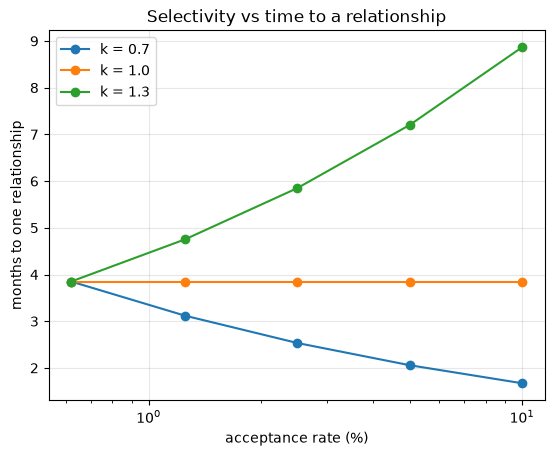

In [10]:
in_bound_min = 132
in_bound_max = 162
acceptance_rate = 0.0062
meet_rate = 0.8
dates_needed = 5.8

observation_days = 16

in_bound_per_month_min = in_bound_min / observation_days * 30
in_bound_per_month_max = in_bound_max / observation_days * 30

print(f"inbound per month (min): {in_bound_per_month_min:.0f}")
print(f"inbound per month (max): {in_bound_per_month_max:.0f}")

matches_min = in_bound_per_month_min * acceptance_rate
matches_max = in_bound_per_month_max * acceptance_rate

dates_min = matches_min * meet_rate
dates_max = matches_max * meet_rate

months_min = dates_needed / dates_max
months_max = dates_needed / dates_min

print(f"matches per month: {matches_min:.2f} to {matches_max:.2f}")
print(f"dates per month:{dates_min:.2f} to {dates_max:.2f}")
print(f"months to one: {months_min:.1f} to {months_max:.1f}")

print()
print("sensitivity to dates_needed")
for d in [3, 5, 8, 12, 20]:
    lo = d / dates_max
    hi = d / dates_min
    print(f"  {d:2d} dates needed -> {lo:4.1f} to {hi:4.1f} months")

base_acceptance = 0.0062
base_dates = 5.8
k = 1.0   # 1 = perfectly coupled, <1 = loosening helps, >1 = loosening hurts

print()
print("acceptance rate vs months to one")
for a in [0.0062, 0.0125, 0.025, 0.05, 0.10]:
    d_needed = base_dates * (a / base_acceptance) ** k
    dates_pm = in_bound_per_month_max * a * meet_rate
    months = d_needed / dates_pm
    print(f"  accept {a*100:5.2f}%  needs {d_needed:5.1f} dates  -> {months:5.1f} months")

base_acceptance = 0.0062
base_dates = 5.8
k = 0.7   # 1 = perfectly coupled, <1 = loosening helps, >1 = loosening hurts

print()
print("acceptance rate vs months to one")
for a in [0.0062, 0.0125, 0.025, 0.05, 0.10]:
    d_needed = base_dates * (a / base_acceptance) ** k
    dates_pm = in_bound_per_month_max * a * meet_rate
    months = d_needed / dates_pm
    print(f"  accept {a*100:5.2f}%  needs {d_needed:5.1f} dates  -> {months:5.1f} months")

base_acceptance = 0.0062
base_dates = 5.8
k = 1.3   # 1 = perfectly coupled, <1 = loosening helps, >1 = loosening hurts

print()
print("acceptance rate vs months to one")
for a in [0.0062, 0.0125, 0.025, 0.05, 0.10]:
    d_needed = base_dates * (a / base_acceptance) ** k
    dates_pm = in_bound_per_month_max * a * meet_rate
    months = d_needed / dates_pm
    print(f"  accept {a*100:5.2f}%  needs {d_needed:5.1f} dates  -> {months:5.1f} months")

import matplotlib.pyplot as plt

acceptance_values = [0.0062, 0.0125, 0.025, 0.05, 0.10]

plt.figure()
for k in [0.7, 1.0, 1.3]:
    months_list = []
    for a in acceptance_values:
        d_needed = base_dates * (a / base_acceptance) ** k
        dates_pm = in_bound_per_month_max * a * meet_rate
        months_list.append(d_needed / dates_pm)
    plt.plot([a * 100 for a in acceptance_values], months_list, marker="o", label=f"k = {k}")

plt.xscale("log")
plt.xlabel("acceptance rate (%)")
plt.ylabel("months to one relationship")
plt.title("Selectivity vs time to a relationship")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("selectivity.png", dpi=150, bbox_inches="tight")
plt.show()
